# Сбор и анализ данных

**Источник:** [ronantakizawa/github-codereview](https://huggingface.co/datasets/ronantakizawa/github-codereview) на Hugging Face —
inline-комментарии людей к pull request'ам из популярных open-source репозиториев (permissive-лицензии, без ботов).

**Как получен:** `uv run python data/fetch_raw.py` — скачивает сплиты test и validation, оставляет только Python
и сохраняет в `data/raw/github_codereview_python.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FIG = Path('../docs/data/fig')
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv('../data/raw/github_codereview_python.csv', keep_default_na=False, na_values=[])
df.shape

(5248, 21)

## Описание набора

In [2]:
with_comment = ~df.is_negative
pd.Series({
    'строк': len(df),
    'репозиториев': df.repo_name.nunique(),
    'PR': df[['repo_name', 'pr_number']].drop_duplicates().shape[0],
    'с замечанием': with_comment.sum(),
    'без замечания': (~with_comment).sum(),
    'доля без замечания': round((~with_comment).mean(), 3),
}, dtype=object).to_frame('значение')

,значение
строк,5248
репозиториев,124
PR,2187
с замечанием,3522
без замечания,1726
доля без замечания,0.329


In [3]:
# пустая строка тоже пропуск: CSV не различает '' и отсутствие значения
fields = pd.DataFrame({
    'тип': df.dtypes.astype(str),
    'пропусков': (df.astype(str).apply(lambda s: s.str.strip()) == '').sum(),
    'уникальных': df.nunique(),
})
fields

,тип,пропусков,уникальных
pr_title,str,0,2133
pr_number,int64,0,1861
repo_name,str,0,124
repo_stars,int64,0,124
repo_language,str,0,12
author_username,str,0,958
reviewer_username,str,1726,439
before_code,str,0,5095
reviewer_comment,str,0,3484
after_code,str,1,5027


Пропуски есть в трёх полях. `reviewer_username` пуст ровно у строк без замечания — у такого кода нет ревьюера,
это не ошибка. Пустые `diff_context` и `after_code` — дефект сбора, их разбирает подготовка данных.

In [4]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
pr_number,5248.0,4300.55,7157.19,4.00,495.00,1525.00,5123.00,87431.0
repo_stars,5248.0,27966.52,32522.25,547.00,5554.00,15289.00,44942.00,212762.0
comment_line,5248.0,15.85,12.25,0.00,0.00,26.00,26.00,26.0
quality_score,5248.0,0.65,0.32,0.07,0.36,0.64,1.00,1.0
comment_length,5248.0,106.79,158.51,16.00,16.00,63.00,132.25,3778.0
before_lines,5248.0,56.02,80.59,1.00,51.00,51.00,51.00,1908.0
after_lines,5248.0,54.20,65.11,2.00,51.00,51.00,51.00,2600.0


топ-15 репозиториев: 49.4% строк


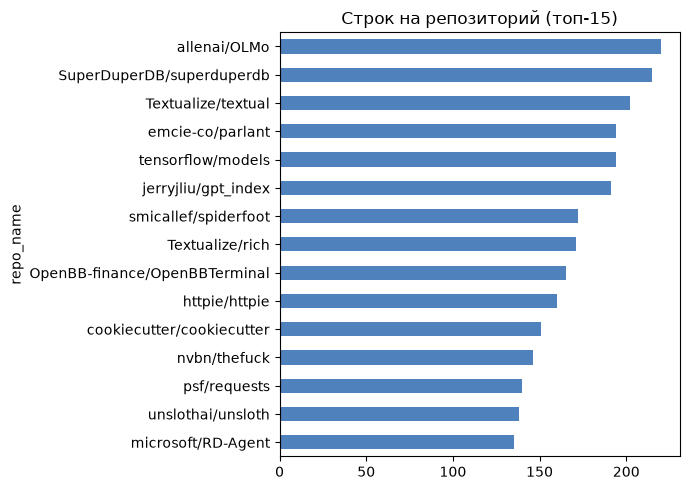

In [5]:
top = df.repo_name.value_counts().head(15)
print(f'топ-15 репозиториев: {top.sum() / len(df):.1%} строк')
top.sort_values().plot.barh(figsize=(7, 5), color='#4f81bd', title='Строк на репозиторий (топ-15)')
plt.tight_layout(); plt.savefig(FIG / 'analysis_repos.png', dpi=120); plt.show()

## Анализ замечаний

              строк   доля
comment_type              
suggestion     2187  0.621
question        706  0.200
bug             176  0.050
refactor        156  0.044
style           100  0.028
performance      80  0.023
security         62  0.018
nitpick          55  0.016


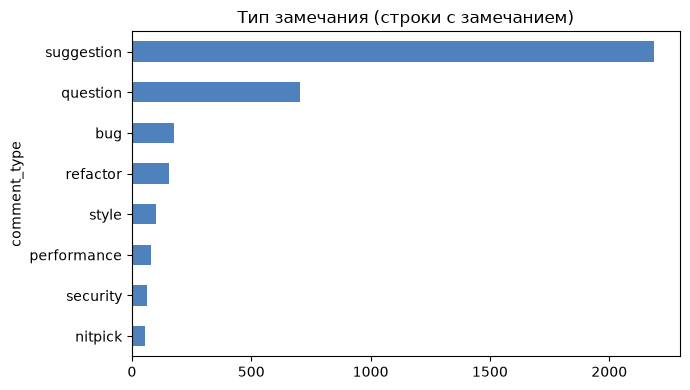

In [6]:
types = df.loc[with_comment, 'comment_type'].value_counts()
print(pd.DataFrame({'строк': types, 'доля': (types / types.sum()).round(3)}).to_string())
types.sort_values().plot.barh(figsize=(7, 4), color='#4f81bd', title='Тип замечания (строки с замечанием)')
plt.tight_layout(); plt.savefig(FIG / 'analysis_comment_types.png', dpi=120); plt.show()

производительность    0.025
безопасность          0.033
именование            0.068
обработка ошибок      0.082
тесты                 0.084


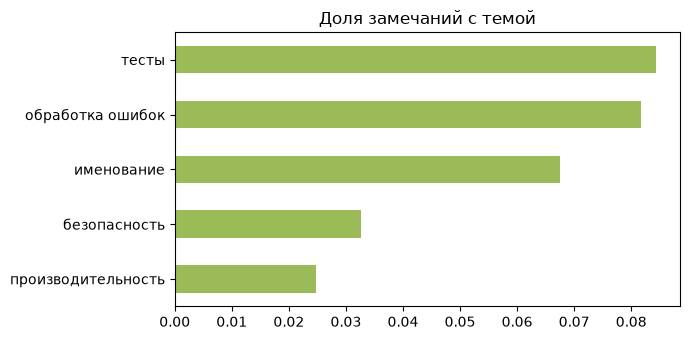

In [7]:
THEMES = {
    'тесты': r'\btest',
    'обработка ошибок': r'except|raise|error|exception',
    'безопасность': r'secur|inject|sanitiz|secret|password|credential|token|auth',
    'именование': r'\bname|rename|naming',
    'производительность': r'perform|slow|memory|cache|complexit|o\(n',
}
comments = df.loc[with_comment, 'reviewer_comment']
themes = pd.Series({k: comments.str.contains(v, case=False, regex=True).mean() for k, v in THEMES.items()}).sort_values()
print(themes.round(3).to_string())
themes.plot.barh(figsize=(7, 3.5), color='#9bbb59', title='Доля замечаний с темой')
plt.tight_layout(); plt.savefig(FIG / 'analysis_themes.png', dpi=120); plt.show()

## Размер полей

In [8]:
diff_chars = df.diff_context.str.len()
sizes = pd.DataFrame({
    'diff, символов': diff_chars,
    'diff, строк': df.diff_context.str.count('\n') + 1,
    'diff, токенов': diff_chars / 3.5,
    'замечание, символов': df.loc[with_comment, 'reviewer_comment'].str.len(),
})
pct = sizes.quantile([.5, .9, .95, .99, 1]).round(0)
pct.index = ['p50', 'p90', 'p95', 'p99', 'max']
pct

,"diff, символов","diff, строк","diff, токенов","замечание, символов"
p50,779.0,21.0,223.0,104.0
p90,2000.0,63.0,571.0,291.0
p95,3028.0,82.0,865.0,405.0
p99,6534.0,180.0,1867.0,850.0
max,13074.0,324.0,3735.0,3778.0


In [9]:
diff_tokens = sizes['diff, токенов']
comment_len = sizes['замечание, символов'].dropna()
rows = [(f'diff > {n} токенов', (diff_tokens > n).sum(), (diff_tokens > n).mean()) for n in (500, 1000, 2000)]
rows += [(f'замечание > {n} символов', (comment_len > n).sum(), (comment_len > n).mean()) for n in (500, 1000)]
pd.DataFrame(rows, columns=['порог', 'строк', 'доля']).round(3)

,порог,строк,доля
0,diff > 500 токенов,1517,0.289
1,diff > 1000 токенов,206,0.039
2,diff > 2000 токенов,35,0.007
3,замечание > 500 символов,118,0.034
4,замечание > 1000 символов,21,0.006


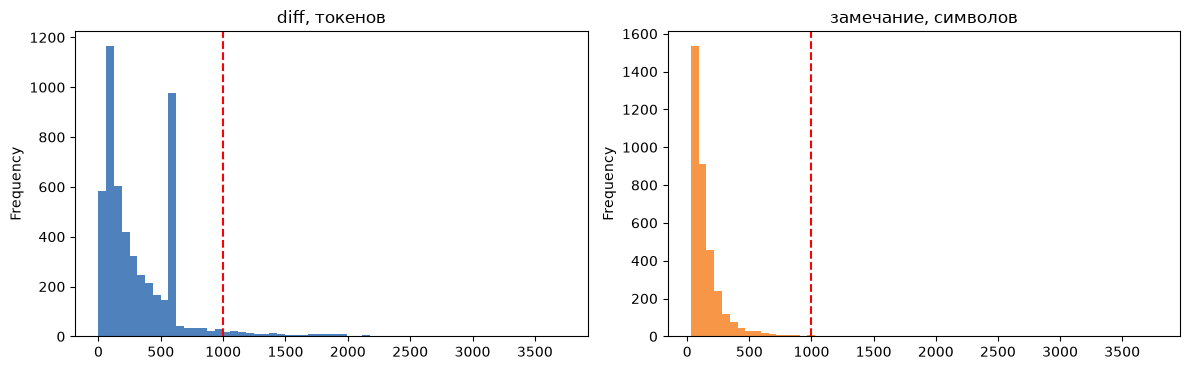

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
diff_tokens.plot.hist(bins=60, ax=ax[0], color='#4f81bd', title='diff, токенов')
ax[0].axvline(1000, color='red', linestyle='--')
comment_len.plot.hist(bins=60, ax=ax[1], color='#f79646', title='замечание, символов')
ax[1].axvline(1000, color='red', linestyle='--')
plt.tight_layout(); plt.savefig(FIG / 'analysis_sizes.png', dpi=120); plt.show()

## Выводы

**Закономерности**
- Треть строк (32,9 %, 1 726 из 5 248) — код, прошедший ревью без замечаний. Агент должен уметь промолчать: это отдельная метрика — доля ложных тревог.
- Среди замечаний преобладают предложения (62,1 %) и вопросы (20,0 %). Критичные типы — bug, security и performance — вместе 9,1 %. Агенту нужен приоритет по severity, иначе редкие критичные замечания потеряются среди мелких.
- По темам чаще всего пишут о тестах (8,4 %), обработке ошибок (8,2 %) и именовании (6,8 %); о безопасности — 3,3 %, о производительности — 2,5 %.

**Размер полей и лимит входа**
- Медиана diff — 223 токена, p95 — 866, p99 — 1 867, максимум — 3 735. Лимит 1 000 токенов отсекает 206 строк (3,9 %), лимит 500 — уже 28,9 %.
- Медиана замечания — 104 символа, p99 — 850. Лимит 1 000 символов отсекает 21 замечание (0,6 %): это длинные обсуждения, а не замечания.
- Рекомендуемый лимит входа агента: diff до 1 000 токенов, замечание до 1 000 символов.

**Ограничения набора**
- Код из open-source, а не банковский: банковских дефектов (ПДн, деньги) почти нет.
- Половина строк (49,4 %) — из 15 репозиториев, доли типов смещены к их привычкам.
- Часть `comment_type` размечена эвристикой, доли типов приблизительные.
- Есть пустые `diff_context` (20 строк) и `after_code` (1 строка) — их убирает подготовка данных.

**Достаточно ли данных.** Для оценки агента — да. Самый редкий тип по severity — performance (major), 80 замечаний: этого хватает, чтобы взять по 20 примеров на класс. 3 522 замечания достаточно для анализа типов и тем. Для обучения модели данных мало, но обучение в проекте не планируется.